In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

# Find the prepared Adult Income dataset
files = list(Path.home().rglob("adult_income_prepared.csv"))

if not files:
    print("ERROR: Adult Income dataset not found.")
else:
    df = pd.read_csv(files[0])

    print("ANA 500 — Week 4: Adult Income Classification")
    print("Dataset loaded successfully")
    print("Rows and columns:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head())

ERROR: Adult Income dataset not found.


In [2]:
from pathlib import Path

# Find Adult Income CSV files in the JupyterLab environment
files = list(Path.cwd().rglob("*.csv"))

for file in files:
    print(file)

/home/3954db08-13ee-47e2-ae05-92fa38cbd4ef/.local/lib/python3.9/site-packages/~umpy/random/tests/data/pcg64dxsm-testset-2.csv
/home/3954db08-13ee-47e2-ae05-92fa38cbd4ef/.local/lib/python3.9/site-packages/~umpy/random/tests/data/pcg64-testset-2.csv
/home/3954db08-13ee-47e2-ae05-92fa38cbd4ef/.local/lib/python3.9/site-packages/~umpy/random/tests/data/sfc64-testset-1.csv
/home/3954db08-13ee-47e2-ae05-92fa38cbd4ef/.local/lib/python3.9/site-packages/~umpy/random/tests/data/philox-testset-2.csv
/home/3954db08-13ee-47e2-ae05-92fa38cbd4ef/.local/lib/python3.9/site-packages/~umpy/random/tests/data/mt19937-testset-2.csv
/home/3954db08-13ee-47e2-ae05-92fa38cbd4ef/.local/lib/python3.9/site-packages/~umpy/random/tests/data/pcg64-testset-1.csv
/home/3954db08-13ee-47e2-ae05-92fa38cbd4ef/.local/lib/python3.9/site-packages/~umpy/random/tests/data/mt19937-testset-1.csv
/home/3954db08-13ee-47e2-ae05-92fa38cbd4ef/.local/lib/python3.9/site-packages/~umpy/random/tests/data/philox-testset-1.csv
/home/3954db08

In [4]:
from pathlib import Path

files = [
    f for f in Path.cwd().rglob("*.csv")
    if "adult" in f.name.lower() or "income" in f.name.lower()
]

for f in files:
    print(f)

In [5]:
import pandas as pd

df = pd.read_csv("adult_income_prepared.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Rows and columns: (32537, 8)
Columns: ['age', 'education', 'education_num', 'workclass', 'occupation', 'hours_per_week', 'marital_status', 'income']


,age,education,education_num,workclass,occupation,hours_per_week,marital_status,income
0,39,Bachelors,13,State-gov,Adm-clerical,40,Never-married,<=50K
1,50,Bachelors,13,Self-emp-not-inc,Exec-managerial,13,Married-civ-spouse,<=50K
2,38,HS-grad,9,Private,Handlers-cleaners,40,Divorced,<=50K
3,53,11th,7,Private,Handlers-cleaners,40,Married-civ-spouse,<=50K
4,28,Bachelors,13,Private,Prof-specialty,40,Married-civ-spouse,<=50K


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Target: 0 = <=50K, 1 = >50K
y = (
    df["income"]
    .astype(str)
    .str.strip()
    .str.replace(".", "", regex=False)
    .eq(">50K")
    .astype(int)
)

# Use the same core variables from our income hypothesis
features = [
    "age", "education", "workclass",
    "occupation", "hours_per_week", "marital_status"
]

X = df[features].copy()

numeric = ["age", "hours_per_week"]
categorical = ["education", "workclass", "occupation", "marital_status"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
])

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data preparation complete!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Income classes:", y.value_counts().to_dict())

/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Data preparation complete!
Training records: 26029
Testing records: 6508
Income classes: {0: 24698, 1: 7839}


In [7]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Build a feed-forward neural network
mlp = Pipeline([
    ("preprocessing", preprocessor),
    ("model", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        max_iter=80,
        early_stopping=True,
        random_state=42
    ))
])

# Train the model
mlp.fit(X_train, y_train)

# Predict income categories
y_pred = mlp.predict(X_test)

print("WEEK 4 NEURAL NETWORK RESULTS")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))

WEEK 4 NEURAL NETWORK RESULTS
Accuracy: 0.8453
Precision: 0.7186
Recall: 0.588
F1 Score: 0.6468

Confusion Matrix:
[[4579  361]
 [ 646  922]]

              precision    recall  f1-score   support

           0       0.88      0.93      0.90      4940
           1       0.72      0.59      0.65      1568

    accuracy                           0.85      6508
   macro avg       0.80      0.76      0.77      6508
weighted avg       0.84      0.85      0.84      6508



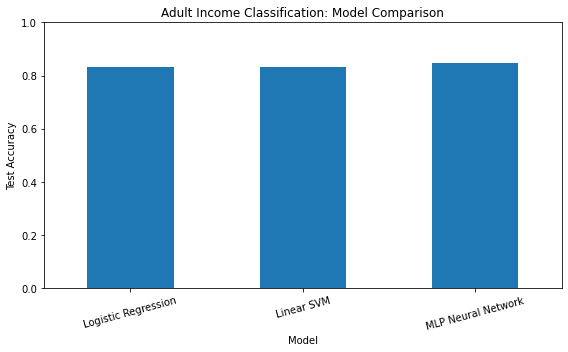

Model comparison saved successfully.


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM", "MLP Neural Network"],
    "Accuracy": [0.8313, 0.8339, 0.8453]
})

ax = comparison.plot(
    x="Model", y="Accuracy",
    kind="bar", legend=False,
    figsize=(8, 5)
)

plt.title("Adult Income Classification: Model Comparison")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("Week4_Model_Comparison.png", dpi=150)
plt.show()

comparison.to_csv("Week4_Model_Comparison.csv", index=False)

print("Model comparison saved successfully.")

## Week 4 — Analysis, Report, and Act

### Research Question
Can education, occupation, workclass, weekly work hours, age, and marital status help classify whether an individual earns more than $50,000 annually?

### Model Development
A feed-forward multilayer perceptron (MLP) neural network was developed using scikit-learn. The dataset contained 32,537 records, divided into 26,029 training records and 6,508 testing records.

Categorical variables were one-hot encoded, and numerical variables were standardized. The neural network used two hidden layers with 32 and 16 neurons, ReLU activation, Adam optimization, and early stopping.

### Results
The neural network achieved:

- Accuracy: 84.53%
- Precision: 71.86%
- Recall: 58.80%
- F1 Score: 64.68%

The model correctly classified 922 higher-income individuals and 4,579 lower-income individuals. It incorrectly classified 361 lower-income individuals as higher-income and missed 646 higher-income individuals.

### Comparison
The neural network outperformed Week 3 Logistic Regression (83.13%) and Linear SVM (83.39%) in overall accuracy.

### Conclusion
The findings support the use of demographic and employment-related variables to classify income categories. The neural network provided the strongest overall accuracy among the three models tested.

However, the model missed approximately 41% of individuals earning more than $50,000. Accuracy alone is therefore insufficient to evaluate performance.

These results demonstrate associations useful for prediction, not proof that the selected variables cause higher income.

### Recommended Action
Retain the neural network as the strongest tested model based on accuracy. Future work should improve recall for the higher-income category, evaluate class imbalance, tune model parameters, and assess potential fairness concerns before using predictions in real-world decisions.

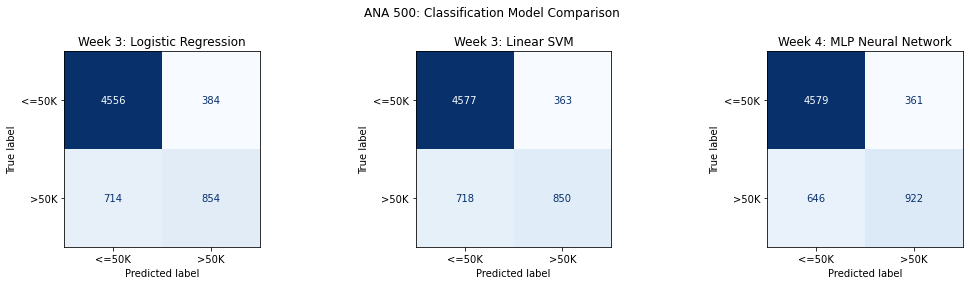

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

matrices = {
    "Week 3: Logistic Regression": np.array([[4556, 384], [714, 854]]),
    "Week 3: Linear SVM": np.array([[4577, 363], [718, 850]]),
    "Week 4: MLP Neural Network": np.array([[4579, 361], [646, 922]])
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, matrix) in zip(axes, matrices.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["<=50K", ">50K"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

plt.suptitle("ANA 500: Classification Model Comparison")
plt.tight_layout()
plt.savefig("ANA500_Three_Model_Confusion_Matrices.png", dpi=150)
plt.show()

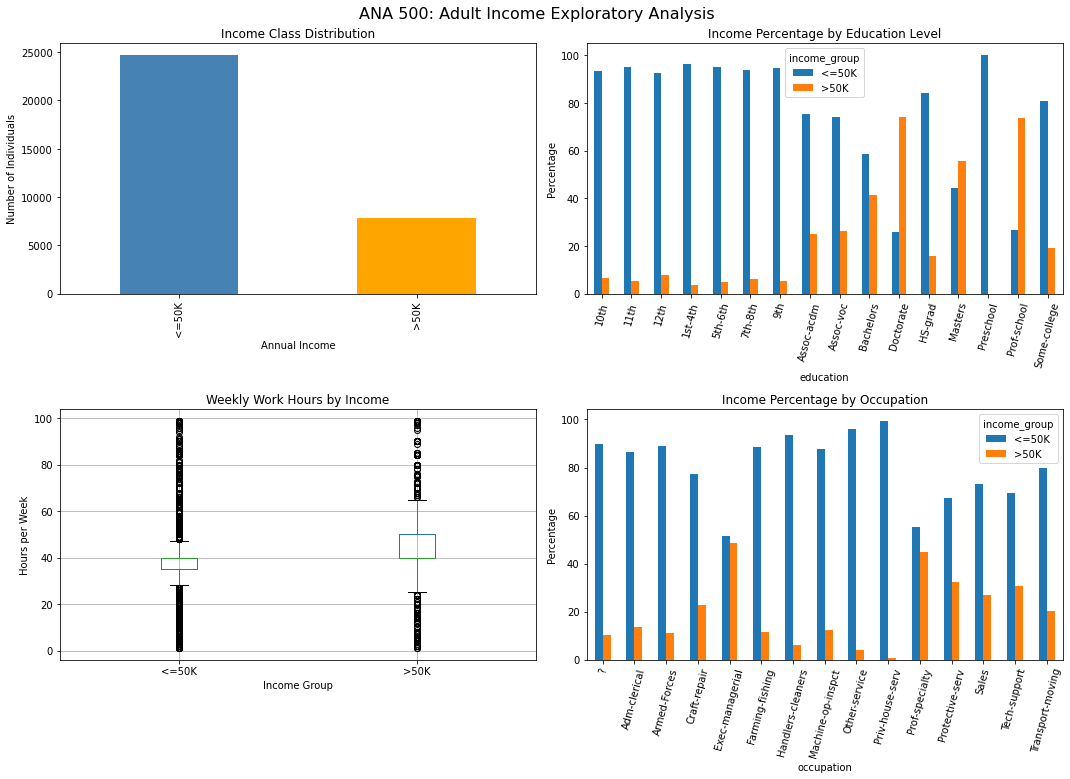

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# Create readable income labels
viz = df.copy()
viz["income_group"] = (
    viz["income"].astype(str).str.strip()
    .str.replace(".", "", regex=False)
)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Income class distribution
viz["income_group"].value_counts().plot(
    kind="bar", ax=axes[0, 0], color=["steelblue", "orange"]
)
axes[0, 0].set_title("Income Class Distribution")
axes[0, 0].set_xlabel("Annual Income")
axes[0, 0].set_ylabel("Number of Individuals")

# 2. Education and income
education = pd.crosstab(
    viz["education"], viz["income_group"], normalize="index"
) * 100
education.plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Income Percentage by Education Level")
axes[0, 1].set_ylabel("Percentage")
axes[0, 1].tick_params(axis="x", rotation=75)

# 3. Weekly work hours by income
viz.boxplot(
    column="hours_per_week",
    by="income_group",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Weekly Work Hours by Income")
axes[1, 0].set_xlabel("Income Group")
axes[1, 0].set_ylabel("Hours per Week")

# 4. Occupation and income
occupation = pd.crosstab(
    viz["occupation"], viz["income_group"], normalize="index"
) * 100
occupation.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Income Percentage by Occupation")
axes[1, 1].set_ylabel("Percentage")
axes[1, 1].tick_params(axis="x", rotation=75)

plt.suptitle("ANA 500: Adult Income Exploratory Analysis", fontsize=16)
plt.tight_layout()
plt.savefig("ANA500_Week2_Exploratory_Analysis.png",
            dpi=150, bbox_inches="tight")
plt.show()

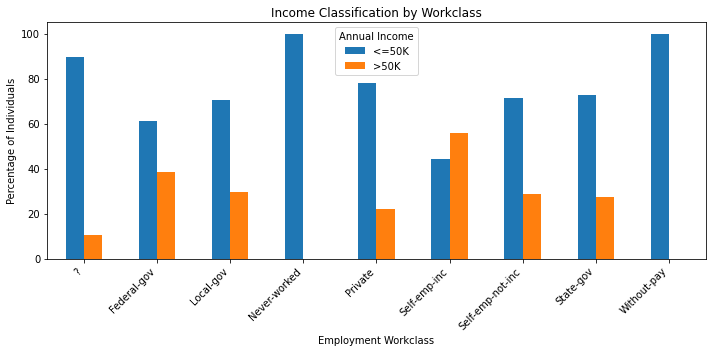

In [11]:
# Workclass vs. income classification
workclass = pd.crosstab(
    viz["workclass"],
    viz["income_group"],
    normalize="index"
) * 100

ax = workclass.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Income Classification by Workclass")
plt.xlabel("Employment Workclass")
plt.ylabel("Percentage of Individuals")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Annual Income")
plt.tight_layout()

plt.savefig(
    "ANA500_Workclass_Income.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## Final Project Conclusion — ANA 500

### Research Question
Can education, occupation, workclass, weekly work hours, age, and marital status help predict whether an individual earns more than $50,000 annually?

### Acquire and Prepare — Week 1
The Adult Income dataset contained 32,537 prepared records. Data preparation involved selecting relevant variables, reviewing income categories, and organizing the dataset for analysis.

### Exploratory Analysis — Week 2
The visualizations examined income distributions and relationships involving education, occupation, workclass, and weekly work hours. These comparisons help identify patterns associated with income classification but do not establish causation.

### Machine Learning — Week 3
Two classification models were evaluated:

- Logistic Regression: 83.13% accuracy
- Linear Support Vector Machine: 83.39% accuracy

Both models demonstrated useful predictive performance but had difficulty identifying some higher-income individuals.

### Neural Network — Week 4
A feed-forward multilayer perceptron neural network was trained using scikit-learn.

Results:
- Accuracy: 84.53%
- Precision: 71.86%
- Recall: 58.80%
- F1 Score: 64.68%

The neural network achieved the highest overall accuracy among the three tested models.

### Limitations
The income categories are imbalanced, with approximately 76% of records belonging to the lower-income group. The neural network still missed 646 higher-income individuals. Additional evaluation is necessary before applying the model to real-world decisions.

### Final Recommendation
Based on test accuracy, the MLP neural network is the strongest of the three evaluated models. Future improvements should focus on recall, class imbalance, hyperparameter tuning, and fairness evaluation.

The project demonstrates the importance of preparing reliable data, visualizing meaningful relationships, comparing models, and using multiple performance metrics to support evidence-based decisions.